### Features used in this dataset (`train.csv`)

- `id`: Row/sample identifier.
- `alpha`: Right Ascension angle (J2000 epoch).
- `delta`: Declination angle (J2000 epoch).
- `u`: Ultraviolet photometric magnitude.
- `g`: Green photometric magnitude.
- `r`: Red photometric magnitude.
- `i`: Near-infrared photometric magnitude.
- `z`: Infrared photometric magnitude.
- `redshift`: Redshift value.
- `spectral_type`: Spectral type category.
- `galaxy_population`: Galaxy population category.
- `class`: Target class (`GALAXY`, `STAR`, `QSO`).


In [3]:
import pandas as pd

train_path = "/workspaces/KagglePredictingStellarClass/data/train.csv"
df = pd.read_csv(train_path)

print("Shape:", df.shape)
print("\nColumn dtypes:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isna().sum().sort_values(ascending=False))

print("\nUnique values per column:")
print(df.nunique())

print("\nFirst 5 rows:")
display(df.head())

df.describe(include="all").transpose()

Shape: (577347, 12)

Column dtypes:
id                     int64
alpha                float64
delta                float64
u                    float64
g                    float64
r                    float64
i                    float64
z                    float64
redshift             float64
spectral_type         object
galaxy_population     object
class                 object
dtype: object

Missing values per column:
id                   0
alpha                0
delta                0
u                    0
g                    0
r                    0
i                    0
z                    0
redshift             0
spectral_type        0
galaxy_population    0
class                0
dtype: int64

Unique values per column:
id                   577347
alpha                439819
delta                444062
u                    577347
g                    577347
r                    577347
i                    577347
z                    577347
redshift             573975
spectr

,id,alpha,delta,u,g,r,i,z,redshift,spectral_type,galaxy_population,class
0,0,147.734256,16.959273,25.472123,21.895559,20.357926,19.257113,18.621057,0.408982,M,Red_Sequence,GALAXY
1,1,127.988677,32.346716,20.778509,19.087062,17.587208,17.226067,16.786433,0.157976,M,Red_Sequence,GALAXY
2,2,179.792648,35.344843,21.035203,21.079128,21.171840,20.582629,20.557366,2.823770,O/B,Blue_Cloud,QSO
3,3,225.818295,48.569421,23.305056,21.050736,19.017754,18.365658,17.914952,0.536099,M,Red_Sequence,GALAXY
4,4,141.836135,19.342852,21.703158,19.471680,18.234449,17.899447,17.616185,0.555761,M,Red_Sequence,GALAXY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id,577347.0,NaN,NaN,NaN,288673.0,166665.86727,0.0,144336.5,288673.0,433009.5,577346.0
alpha,577347.0,NaN,NaN,NaN,181.616673,96.242941,0.011684,132.161499,188.681465,231.829693,359.99981
delta,577347.0,NaN,NaN,NaN,21.834654,18.93357,-17.966988,2.474097,21.484412,36.98831,79.158322
u,577347.0,NaN,NaN,NaN,22.441926,2.018135,-0.139225,20.97709,22.570222,23.869103,28.253263
g,577347.0,NaN,NaN,NaN,21.007273,1.795426,13.535483,19.865005,21.46782,22.292715,27.620208
r,577347.0,NaN,NaN,NaN,19.962811,1.648964,12.579407,18.820671,20.431153,21.164096,25.254499
i,577347.0,NaN,NaN,NaN,19.378911,1.580059,11.962781,18.30682,19.631642,20.608191,27.910853
z,577347.0,NaN,NaN,NaN,19.041136,1.584365,11.682803,17.973192,19.188598,20.162111,26.826867
redshift,577347.0,NaN,NaN,NaN,0.723135,0.81007,-0.00997,0.181052,0.497525,0.88139,7.01078
spectral_type,577347,4,M,303323,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Next-step EDA

This section checks class balance, categorical distributions, numeric distributions, and feature relationships.

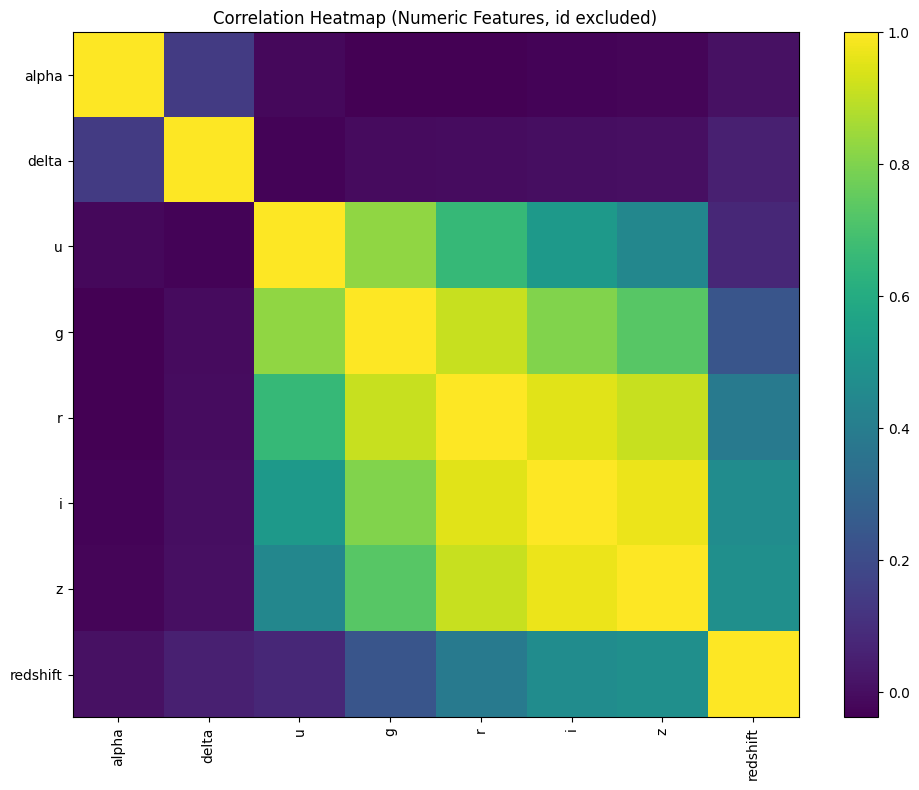

Top absolute correlations (excluding self-correlation):


,feature_1,feature_2,correlation
0,i,z,0.968715
1,r,i,0.953550
2,r,z,0.913341
3,g,r,0.912066
4,u,g,0.826880
5,g,i,0.805020
6,g,z,0.731737
7,u,r,0.659410
8,u,i,0.521811
9,z,redshift,0.480860



Mutual Information scores (higher = more useful for predicting class):


,mutual_info_score
redshift,0.514989
spectral_type,0.361931
galaxy_population,0.276946
z,0.211516
u,0.178881
g,0.174587
i,0.158248
alpha,0.139565
delta,0.130563
r,0.097945


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

# Correlation matrix for numeric features only (no class_code — it's nominal)
num_cols = df.select_dtypes(include=["number"]).columns.tolist()
feat_cols = [c for c in num_cols if c != "id"]  # drop id, it's not a feature

corr = df[feat_cols].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, aspect="auto")
ax.set_xticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr.index)))
ax.set_yticklabels(corr.index)
ax.set_title("Correlation Heatmap (Numeric Features, id excluded)")
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

# Strong pairwise correlations (upper triangle only)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
corr_pairs = upper.stack().sort_values(key=lambda s: s.abs(), ascending=False)
top_corr = corr_pairs.head(12).reset_index()
top_corr.columns = ["feature_1", "feature_2", "correlation"]
print("Top absolute correlations (excluding self-correlation):")
display(top_corr)

# --- Mutual Information vs class (correct approach for nominal target) ---
# Encode all features: label-encode categoricals, pass numerics as-is
cat_cols = df.select_dtypes(exclude=["number"]).columns.tolist()
cat_features = [c for c in cat_cols if c != "class"]

X = df[feat_cols].copy()
for col in cat_features:
    X[col] = LabelEncoder().fit_transform(df[col])

y = LabelEncoder().fit_transform(df["class"])

mi_scores = mutual_info_classif(X, y, discrete_features=False, random_state=42)
mi_df = (
    pd.Series(mi_scores, index=X.columns)
    .sort_values(ascending=False)
    .rename("mutual_info_score")
    .to_frame()
)
print("\nMutual Information scores (higher = more useful for predicting class):")
display(mi_df)

Engineered feature set:
alpha                float64
delta                float64
redshift             float64
spectral_type          int64
galaxy_population      int64
u_g                  float64
g_r                  float64
r_i                  float64
i_z                  float64
dtype: object


,alpha,delta,redshift,spectral_type,galaxy_population,u_g,g_r,r_i,i_z
0,147.734256,16.959273,0.408982,2,1,3.576564,1.537632,1.100813,0.636056
1,127.988677,32.346716,0.157976,2,1,1.691447,1.499854,0.361141,0.439634
2,179.792648,35.344843,2.823770,3,0,-0.043925,-0.092712,0.589211,0.025263
3,225.818295,48.569421,0.536099,2,1,2.254320,2.032982,0.652096,0.450706
4,141.836135,19.342852,0.555761,2,1,2.231478,1.237231,0.335002,0.283262


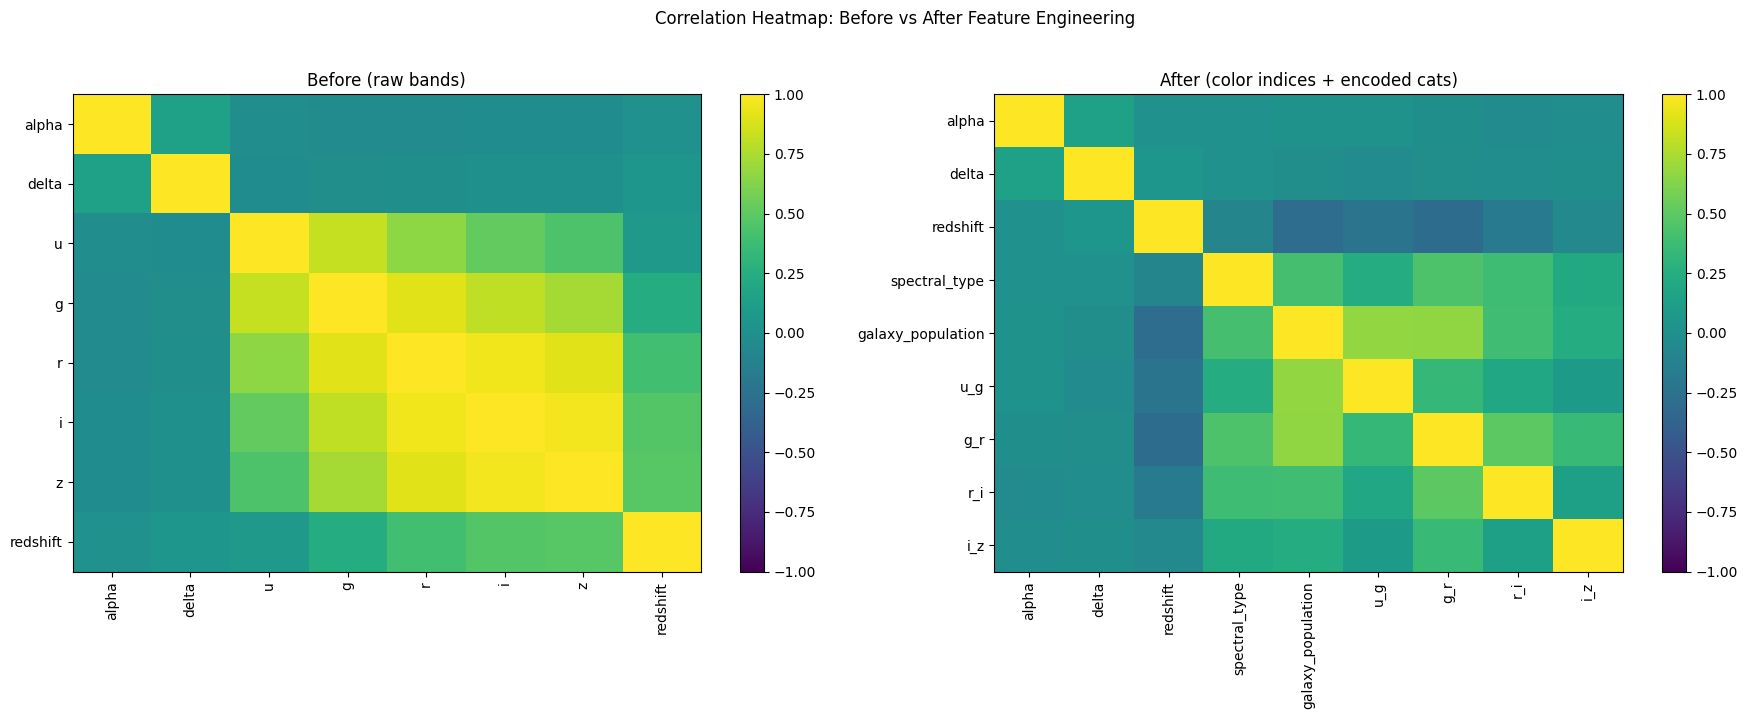


Max pairwise correlation  BEFORE: 0.969
Max pairwise correlation  AFTER:  0.679


In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# --- Feature Engineering ---
df_eng = df.drop(columns=["id"]).copy()

# 1. Color indices (spectrum shape, less correlated than raw bands)
df_eng["u_g"] = df_eng["u"] - df_eng["g"]
df_eng["g_r"] = df_eng["g"] - df_eng["r"]
df_eng["r_i"] = df_eng["r"] - df_eng["i"]
df_eng["i_z"] = df_eng["i"] - df_eng["z"]

# 2. Drop raw photometric bands (replaced by color indices)
df_eng = df_eng.drop(columns=["u", "g", "r", "i", "z"])

# 3. Label-encode categoricals
for col in ["spectral_type", "galaxy_population"]:
    df_eng[col] = LabelEncoder().fit_transform(df_eng[col])

print("Engineered feature set:")
print(df_eng.drop(columns=["class"]).dtypes)
display(df_eng.drop(columns=["class"]).head())

# --- Correlation heatmap of engineered features ---
feat_eng_cols = [c for c in df_eng.columns if c != "class"]
corr_eng = df_eng[feat_eng_cols].corr()

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Before
feat_before = [c for c in df.columns if c not in ("id", "class", "spectral_type", "galaxy_population")]
corr_before = df[feat_before].corr()
im0 = axes[0].imshow(corr_before, aspect="auto", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(corr_before.columns)))
axes[0].set_xticklabels(corr_before.columns, rotation=90)
axes[0].set_yticks(range(len(corr_before.index)))
axes[0].set_yticklabels(corr_before.index)
axes[0].set_title("Before (raw bands)")
fig.colorbar(im0, ax=axes[0])

# After
im1 = axes[1].imshow(corr_eng, aspect="auto", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(corr_eng.columns)))
axes[1].set_xticklabels(corr_eng.columns, rotation=90)
axes[1].set_yticks(range(len(corr_eng.index)))
axes[1].set_yticklabels(corr_eng.index)
axes[1].set_title("After (color indices + encoded cats)")
fig.colorbar(im1, ax=axes[1])

plt.suptitle("Correlation Heatmap: Before vs After Feature Engineering", y=1.02)
plt.tight_layout()
plt.show()

# Max off-diagonal correlation before vs after
def max_off_diag(corr_matrix):
    upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
    return upper.stack().abs().max()

print(f"\nMax pairwise correlation  BEFORE: {max_off_diag(corr_before):.3f}")
print(f"Max pairwise correlation  AFTER:  {max_off_diag(corr_eng):.3f}")

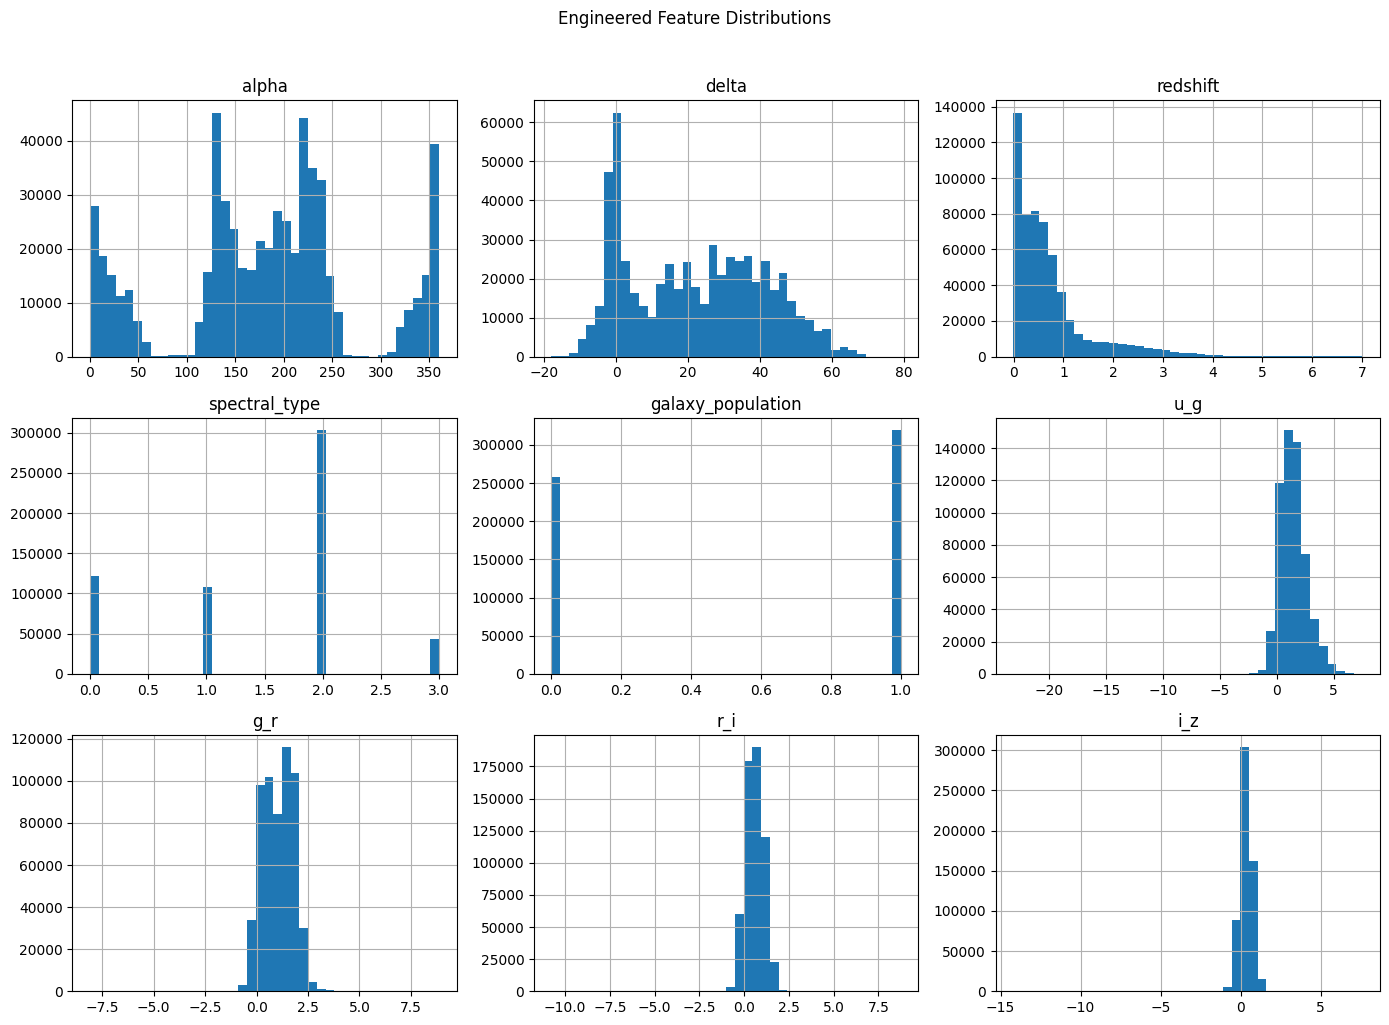

Engineered feature statistics:


,alpha,delta,redshift,spectral_type,galaxy_population,u_g,g_r,r_i,i_z
count,577347.000,577347.000,577347.000,577347.000,577347.000,577347.000,577347.000,577347.000,577347.000
mean,181.617,21.835,0.723,1.464,0.554,1.435,1.044,0.584,0.338
std,96.243,18.934,0.810,0.907,0.497,1.142,0.736,0.497,0.396
min,0.012,-17.967,-0.010,0.000,0.000,-23.156,-8.104,-10.758,-14.211
25%,132.161,2.474,0.181,1.000,0.000,0.599,0.420,0.216,0.094
50%,188.681,21.484,0.498,2.000,1.000,1.333,1.076,0.570,0.344
75%,231.830,36.988,0.881,2.000,1.000,2.088,1.646,0.947,0.590
max,360.000,79.158,7.011,3.000,1.000,7.523,8.874,8.749,7.625



Approximate outlier rate by engineered column (% using IQR rule):
redshift             9.11
u_g                  1.81
i_z                  1.39
r_i                  0.13
g_r                  0.09
alpha                0.00
galaxy_population    0.00
delta                0.00
spectral_type        0.00
dtype: float64


In [14]:
import matplotlib.pyplot as plt

# --- Engineered Feature Distributions ---
eng_numeric_cols = df_eng.select_dtypes(include=["number"]).columns.tolist()
_ = df_eng[eng_numeric_cols].hist(figsize=(14, 10), bins=40)
plt.suptitle("Engineered Feature Distributions", y=1.02)
plt.tight_layout()
plt.show()

# Feature statistics after engineering
print("Engineered feature statistics:")
display(df_eng[eng_numeric_cols].describe().round(3))

# Outlier signal via IQR rule on engineered features
q1_eng = df_eng[eng_numeric_cols].quantile(0.25)
q3_eng = df_eng[eng_numeric_cols].quantile(0.75)
iqr_eng = q3_eng - q1_eng
outlier_rate_eng = (((df_eng[eng_numeric_cols] < (q1_eng - 1.5 * iqr_eng)) | (df_eng[eng_numeric_cols] > (q3_eng + 1.5 * iqr_eng))).mean() * 100).sort_values(ascending=False)
print("\nApproximate outlier rate by engineered column (% using IQR rule):")
print(outlier_rate_eng.round(2))

Class counts:
class
GALAXY    377480
QSO       117143
STAR       82724
Name: count, dtype: int64

Class percentages (%):
class
GALAXY    65.38
QSO       20.29
STAR      14.33
Name: proportion, dtype: float64


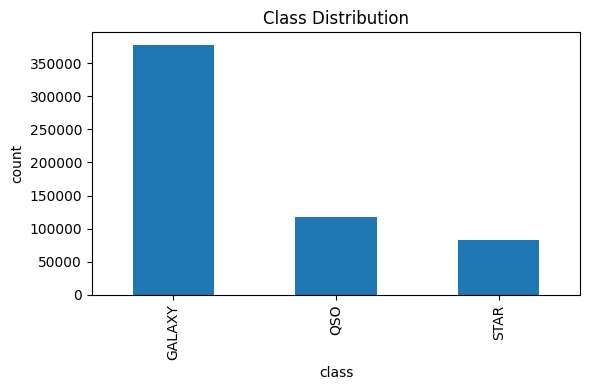


=== Original Categorical Features (for reference) ===

spectral_type:
spectral_type
M      303323
A/F    122122
G/K    108546
O/B     43356
Name: count, dtype: int64

galaxy_population:
galaxy_population
Red_Sequence    319565
Blue_Cloud      257782
Name: count, dtype: int64


In [16]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder

# --- Class Distribution (from engineered data) ---
class_counts = df_eng["class"].value_counts()
class_pct = df_eng["class"].value_counts(normalize=True).mul(100).round(2)
print("Class counts:")
print(class_counts)
print("\nClass percentages (%):")
print(class_pct)

ax = class_counts.plot(kind="bar", figsize=(6, 4), title="Class Distribution")
ax.set_xlabel("class")
ax.set_ylabel("count")
plt.tight_layout()
plt.show()

# --- Categorical feature summaries (from original data for reference) ---
print("\n=== Original Categorical Features (for reference) ===")
for col in ["spectral_type", "galaxy_population"]:
    print(f"\n{col}:")
    print(df[col].value_counts(dropna=False))